# 04 Cross-validation, test audit and fairness

Owner: Zhang Enhao. The only notebook that touches the test set, exactly once (Section 4).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

from src.data import load_day, time_split, load_events
from src.models import BASE_FORMULA
from src import remedies
from src.cv import (forward_chain_cv, forward_chain_oof, shuffled_kfold_cv,
                    cv_summary, fit_predict, FIRST_TRAIN_END)

FIG = ROOT / "figures"
BLUE, ORANGE = "#2a78d6", "#eb6834"   # categorical slots 1 and 2
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": MUTED, "axes.labelcolor": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10})

df = load_day()
train, test = time_split(df)
print(len(train), "training days,", len(test), "test days (test set not used before Section 4)")

584 training days, 147 test days (test set not used before Section 4)


## 1. Cross-validation design

We compare models by RMSE, measured in rentals per day. We picked RMSE mainly because the unit is easy to read, and because it punishes the days where the model is off by a lot more heavily.

We did not shuffle the data for cross-validation. The days are in time order, and neighbouring days tend to look alike; the base model's Durbin-Watson statistic of 1.24 also shows clear positive autocorrelation in the residuals. So we move forward in time: each fold only uses past days to predict the next stretch, and there are three validation blocks, Feb-Apr, Apr-Jun and Jun-Aug 2012.

At first we ended the first training block at the end of 2011. Fold 1 then had an RMSE of 1,871, and we found that `yr` was 0 for every day in that training block, so the model had no chance to learn that demand in 2012 was higher overall. We therefore extended the first training block to the end of January 2012, so it covers all 12 months and also some 2012 days.

The same exclusion rules are used in every block, and we do not change a rule because one fold looks bad. One clear limitation of this design is that the validation blocks fall in Feb-Aug, while the test set runs from Aug to Dec, so the seasons do not fully match. We check this again in Section 4.

In [2]:
# Why the first training block cannot stop at 2011-12-31
only_2011 = train[train["dteday"] <= "2011-12-31"]
print("yr values in a 2011-only training block:", only_2011["yr"].unique())
print("First training block used instead ends on", FIRST_TRAIN_END)

forward_chain_cv(BASE_FORMULA, train)[["fold", "train_end", "val_start", "val_end",
                                       "val_months", "n_train", "n_val"]]

yr values in a 2011-only training block: [0]
First training block used instead ends on 2012-01-31


,fold,train_end,val_start,val_end,val_months,n_train,n_val
0,1,2012-01-31,2012-02-01,2012-04-03,Feb-Apr,396,63
1,2,2012-04-03,2012-04-04,2012-06-05,Apr-Jun,459,63
2,3,2012-06-05,2012-06-06,2012-08-06,Jun-Aug,522,62


## 2. Forward-chaining vs shuffled CV

The remedied model is added automatically once Ma freezes `REMEDIED_FORMULA` (C1b, 26 Oct). If it uses a log outcome or WLS weights, put those settings in `REMEDIED_KW`.

In [3]:
NUMERIC_FORMULA = ("cnt ~ season + yr + mnth + holiday + weekday + workingday + weathersit"
                   " + temp + atemp + hum + windspeed")   # proposal pilot, for reference only

REMEDIED_KW = {}   # e.g. {"log_y": True} or {"weights": some_function}; set when Ma freezes the model
REMEDIED_READY = remedies.REMEDIED_FORMULA is not None

def remedied_exclude(d):
    return remedies.exclusion_mask(d, load_events())

candidates = {
    "Numeric coding (proposal)": (NUMERIC_FORMULA, {}),
    "Base model": (BASE_FORMULA, {}),
}
if REMEDIED_READY:
    candidates["Remedied model"] = (remedies.REMEDIED_FORMULA,
                                    {"exclude": remedied_exclude, **REMEDIED_KW})
else:
    print("Remedied model not frozen yet: only the base models are compared for now.")

rows, per_fold = [], []
for name, (formula, kw) in candidates.items():
    fc = forward_chain_cv(formula, train, **kw)
    sh = shuffled_kfold_cv(formula, train, **kw)
    f, s = cv_summary(fc), cv_summary(sh)
    rows.append({"model": name,
                 "forward RMSE": f["mean_rmse"], "forward SE": f["se"],
                 "shuffled RMSE": s["mean_rmse"], "shuffled SE": s["se"],
                 "shuffled lower by (%)": 100 * (1 - s["mean_rmse"] / f["mean_rmse"])})
    per_fold.append(fc.assign(model=name)[["model", "fold", "val_months", "rmse"]])

cv_table = pd.DataFrame(rows).set_index("model")
cv_table.round(0)

Remedied model not frozen yet: only the base models are compared for now.


,forward RMSE,forward SE,shuffled RMSE,shuffled SE,shuffled lower by (%)
model,,,,,
Numeric coding (proposal),1164.0,25.0,815.0,45.0,30.0
Base model,1018.0,71.0,728.0,51.0,29.0


In [4]:
# Forward-chaining RMSE per validation block
folds = pd.concat(per_fold)
order = folds.drop_duplicates("fold").sort_values("fold")["val_months"].tolist()
folds.pivot(index="model", columns="val_months", values="rmse")[order].round(0)

val_months,Feb-Apr,Apr-Jun,Jun-Aug
model,,,
Base model,1155.0,917.0,981.0
Numeric coding (proposal),1196.0,1115.0,1181.0


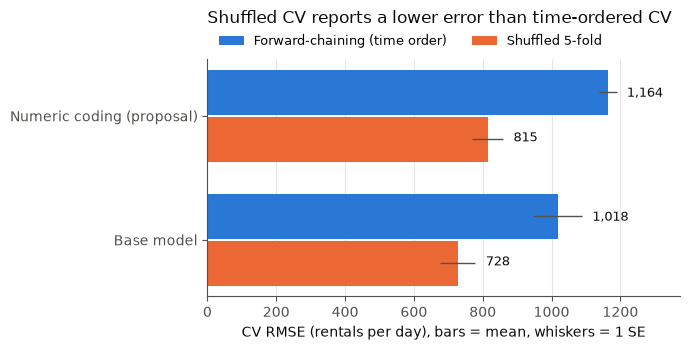

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.6))
y = np.arange(len(cv_table))
h = 0.36
ax.barh(y - h / 2 - 0.01, cv_table["forward RMSE"], height=h, color=BLUE,
        xerr=cv_table["forward SE"], error_kw={"ecolor": MUTED, "lw": 1}, label="Forward-chaining (time order)")
ax.barh(y + h / 2 + 0.01, cv_table["shuffled RMSE"], height=h, color=ORANGE,
        xerr=cv_table["shuffled SE"], error_kw={"ecolor": MUTED, "lw": 1}, label="Shuffled 5-fold")
for yi, (fv, sv) in enumerate(zip(cv_table["forward RMSE"], cv_table["shuffled RMSE"])):
    fse, sse = cv_table["forward SE"].iloc[yi], cv_table["shuffled SE"].iloc[yi]
    ax.text(fv + fse + 30, yi - h / 2, f"{fv:,.0f}", va="center", fontsize=9, color=INK)
    ax.text(sv + sse + 30, yi + h / 2, f"{sv:,.0f}", va="center", fontsize=9, color=INK)
ax.set_yticks(y, cv_table.index)
ax.invert_yaxis()
ax.set_xlabel("CV RMSE (rentals per day), bars = mean, whiskers = 1 SE")
ax.xaxis.grid(True, color=GRID); ax.set_axisbelow(True)
ax.set_xlim(0, cv_table["forward RMSE"].max() * 1.18)
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, fontsize=9)
ax.set_title("Shuffled CV reports a lower error than time-ordered CV", loc="left", color=INK, pad=26)
fig.tight_layout()
fig.savefig(FIG / "04_cv_forward_vs_shuffled.png", dpi=150, bbox_inches="tight")

Both models get an RMSE about 30% lower under shuffled CV than under time-ordered CV, for example 728 vs 1,018 for the base model. The reason is fairly direct: after shuffling, the days just before and after a validation day are very likely already in the training set, so the model has in effect seen very similar cases. The error it reports is too low and cannot be taken as the real out-of-sample performance.

After switching the categorical variables to dummies, the time-ordered RMSE fell from 1,164 to 1,018, and it is lower in all three blocks. So the coding problem the professor pointed out did not only make the diagnostic plots look wrong; it also hurt out-of-sample prediction.

Of the three blocks, the first one (Feb-Apr) has the largest error, an RMSE of 1,155. One likely reason is that at that point only one month of the training data is from 2012.

**[TODO-LATER T2b · after 26 Oct]** Base vs remedied: does the remedy lower forward RMSE by more than about one SE?

## 3. Fairness: errors by day type and weather

Here we group the errors in two ways: by day type (working day, weekend, holiday) and by weather. We chose these two because they are basically known before the day starts, so an operator could actually use them to plan bikes in advance.

We did not group by casual share, because casual share is calculated from the day's final rental count. You only know which group a day belongs to after the day is over, so using it here would be a kind of hindsight.

Every prediction here comes from a model that did not see that day, and the predictions cover 188 days from February to August 2012. Residuals are defined as actual minus predicted, so a positive value means the model under-predicted demand that day, which in practice could mean too few bikes.

In [6]:
fair_formula, fair_kw = ((remedies.REMEDIED_FORMULA, {"exclude": remedied_exclude, **REMEDIED_KW})
                          if REMEDIED_READY else (BASE_FORMULA, {}))
oof = forward_chain_oof(fair_formula, train, **fair_kw)
oof["resid"] = oof["actual"] - oof["pred"]
oof["pct_err"] = 100 * oof["resid"] / oof["actual"]
oof["day_type"] = np.select([oof["holiday"] == 1, oof["weekday"].isin([0, 6])],
                            ["Holiday", "Weekend"], default="Working day")
oof["weather"] = oof["weathersit"].map({1: "1 Clear", 2: "2 Mist/cloud", 3: "3 Rain/snow"})

def group_errors(d, col):
    g = d.groupby(col)
    return pd.DataFrame({
        "n days": g.size(),
        "mean actual": g["actual"].mean(),
        "mean residual": g["resid"].mean(),
        "median % error": g["pct_err"].median(),
        "RMSE": g["resid"].apply(lambda r: np.sqrt(np.mean(r ** 2))),
    })

print("Model used:", "remedied" if REMEDIED_READY else "base (provisional)")
by_day = group_errors(oof, "day_type").reindex(["Working day", "Weekend", "Holiday"])
by_weather = group_errors(oof, "weather")
display(by_day.round(1))
display(by_weather.round(1))

Model used: base (provisional)


,n days,mean actual,mean residual,median % error,RMSE
day_type,,,,,
Working day,130,5840.2,229.1,6.2,975.1
Weekend,54,5623.7,205.1,1.9,1149.3
Holiday,4,5736.2,333.0,7.9,663.2


,n days,mean actual,mean residual,median % error,RMSE
weather,,,,,
1 Clear,131,6097.5,262.2,6.3,896.4
2 Mist/cloud,54,5174.5,152.9,2.0,1267.0
3 Rain/snow,3,2551.7,-141.0,15.1,1256.2


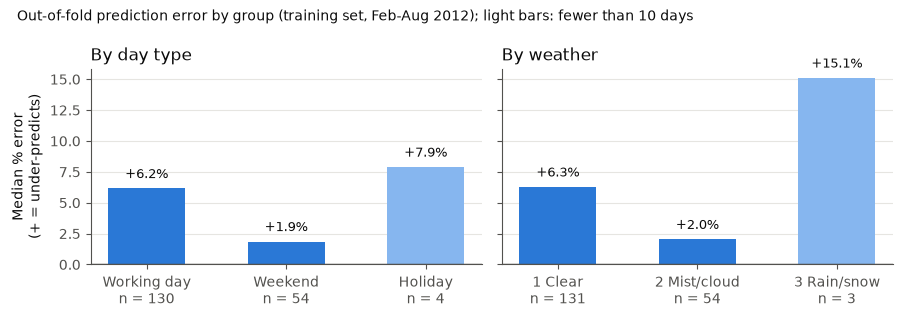

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, tab, title in [(axes[0], by_day, "By day type"), (axes[1], by_weather, "By weather")]:
    vals = tab["median % error"]
    colors = [BLUE if n >= 10 else "#86b6ef" for n in tab["n days"]]
    ax.bar(range(len(vals)), vals, color=colors, width=0.55)
    ax.axhline(0, color=MUTED, lw=1)
    for i, (v, n) in enumerate(zip(vals, tab["n days"])):
        ax.text(i, v + (0.6 if v >= 0 else -0.6), f"{v:+.1f}%", ha="center",
                va="bottom" if v >= 0 else "top", fontsize=9, color=INK)
    ax.set_xticks(range(len(vals)), [f"{g}\nn = {n}" for g, n in zip(vals.index, tab["n days"])])
    ax.set_title(title, loc="left", color=INK)
    ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)
axes[0].set_ylabel("Median % error\n(+ = under-predicts)")
fig.suptitle("Out-of-fold prediction error by group (training set, Feb-Aug 2012); "
             "light bars: fewer than 10 days", x=0.01, ha="left", color=INK, fontsize=10)
fig.tight_layout()
fig.savefig(FIG / "04_fairness_groups.png", dpi=150, bbox_inches="tight")

Day type is also linked to the type of rider. Jiang's EDA earlier shows that casual riders are concentrated on weekends and holidays, so looking at day type also indirectly answers whether the model is accurate on days with more tourists.

Some groups are really small, though: there are only 4 holidays and 3 rain/snow days, so we do not want to draw strong conclusions from them. For example, the rain/snow group has a median error of +15%, but its mean residual is negative, so the two do not even agree on the direction.

One more point: days removed by the rules, such as hurricanes or government closures, are outside what this model is meant to predict. In reality these extreme days are exactly when emergency planning is needed most, so this is a practical ethical limit on where the model can be used.

**[TODO-LATER T4b · after 26 Oct]** Results with the remedied model: which groups are under- or over-predicted, by how much, and what it means for an operator. Base-model draft: every group has a positive mean residual (the system kept growing within 2012), weekends have a smaller median error than working days (+1.9% vs +6.2%) but a larger RMSE (1,149 vs 975). Compare groups with each other, not with zero.

## 4. Test-set audit (run exactly once)

The test set is used only once, and only to test the final model we have already chosen. Before running it, we fix three things: the final remedied model, the exclusion rules, and the text of Sections 1-3.

Which test days are excluded is decided only by the rules and the external event table set earlier. We do not look at the test errors first and then decide which days to drop; for example, the Sandy days are handled by the hurricane rule we already wrote.

We then report the overall RMSE on the test days that are kept, and also split the RMSE by month and put it next to the CV results, to see how big the seasonal gap mentioned above really is. After the test run, we do not go back and change the model.

(To run: set `RUN_TEST_AUDIT = True` below, once.)

In [8]:
RUN_TEST_AUDIT = False

if RUN_TEST_AUDIT:
    assert REMEDIED_READY, "freeze REMEDIED_FORMULA before the test audit"
    events = load_events()
    ex_train = remedies.exclusion_mask(train, events)
    ex_test = remedies.exclusion_mask(test, events)
    fit_df = train[~ex_train["excluded"].to_numpy()]
    kept = test[~ex_test["excluded"].to_numpy()].copy()

    kept["pred"] = fit_predict(remedies.REMEDIED_FORMULA, fit_df, kept,
                               REMEDIED_KW.get("log_y", False), REMEDIED_KW.get("weights"))
    kept["resid"] = kept["cnt"] - kept["pred"]
    test_rmse = float(np.sqrt(np.mean(kept["resid"] ** 2)))
    cv_rmse = cv_table.loc["Remedied model", "forward RMSE"]

    print(f"Test RMSE ({len(kept)} days kept): {test_rmse:,.0f}")
    print(f"Forward-chaining CV RMSE:        {cv_rmse:,.0f}")
    print("\nTest days excluded by the rules:")
    display(test.loc[ex_test["excluded"].to_numpy(), ["dteday"]].join(ex_test[ex_test["excluded"]]))
    display(kept.groupby(kept["dteday"].dt.strftime("%Y-%m"))["resid"]
                .agg(n="size", RMSE=lambda r: np.sqrt(np.mean(r ** 2)), mean_resid="mean").round(0))
else:
    print("Test audit not run yet.")

Test audit not run yet.


**[TODO-LATER T10 · after the audit]** Test RMSE vs CV RMSE and how much of the gap is seasonal (by-month table); which test days the rules excluded and why; where the model can and cannot be used.

## 5. Final model refit on all 731 days

Same specification as the audited model, refitted on train + test (minus rule-excluded days), for the final reported coefficients.

In [9]:
if RUN_TEST_AUDIT:
    ex_all = remedies.exclusion_mask(df, load_events())
    full = df[~ex_all["excluded"].to_numpy()]
    lhs, rhs = remedies.REMEDIED_FORMULA.split("~", 1)
    f = f"np.log({lhs.strip()}) ~{rhs}" if REMEDIED_KW.get("log_y") else remedies.REMEDIED_FORMULA
    w = REMEDIED_KW.get("weights")
    final = (smf.wls(f, full, weights=w(full)) if w else smf.ols(f, full)).fit()
    display(pd.DataFrame({"coef": final.params, "2.5%": final.conf_int()[0],
                          "97.5%": final.conf_int()[1], "p": final.pvalues}).round(3))
else:
    print("Final refit runs after the test audit.")

Final refit runs after the test audit.
